In [1]:
# Assignment 3: Support Vector Machine (SVM) Classification
# Student Name: Anmol Sharma
# Course: Machine Learning (IIT MANDI DSAI)

# ---------------------------------------------------------
# 1. Introduction, Configuration & Loading
# ---------------------------------------------------------
# Goal: Predict term deposit subscription using SVM.
# Constraints: Implement SVM from scratch (SMO algorithm), no scikit-learn for model.
#
# Configuration Notes:
# - Subsampling to 5000 samples to allow pure Python training in a reasonable time.
# - MAX_ITER=15 (Stability Counter) provides the best balance between speed and convergence.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style for clear report visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 150

# Configuration Constants
TRAIN_FILE = 'new_train.csv'
SAMPLE_SIZE = 5000
RANDOM_STATE = 42

# Max iterations for the SMO algorithm (stability counter)
# Controls how many consecutive stable passes we wait for before stopping
MAX_ITER = 15

print(f"Configuration Set: Sample Size={SAMPLE_SIZE}, Max Iter={MAX_ITER}")

# Load the dataset immediately
print(f"Loading data from '{TRAIN_FILE}'...")
df_raw = pd.read_csv(TRAIN_FILE)
print(f"✓ Data loaded successfully. Shape: {df_raw.shape}")

Configuration Set: Sample Size=5000, Max Iter=15
Loading data from 'new_train.csv'...
✓ Data loaded successfully. Shape: (32950, 16)


In [2]:
# Basic Data Exploration
print("\n--- Data Exploration ---")
print(f"Shape: {df_raw.shape} (Rows, Columns)")
print("\nFirst 5 rows:")
print(df_raw.head())
print("\nColumn Info:")
print(df_raw.info())
print("\nTarget Distribution:")
print(df_raw['y'].value_counts())
print("------------------------")


--- Data Exploration ---
Shape: (32950, 16) (Rows, Columns)

First 5 rows:
   age           job   marital          education  default housing loan  \
0   49   blue-collar   married           basic.9y  unknown      no   no   
1   37  entrepreneur   married  university.degree       no      no   no   
2   78       retired   married           basic.4y       no      no   no   
3   36        admin.   married  university.degree       no     yes   no   
4   59       retired  divorced  university.degree       no      no   no   

     contact month day_of_week  duration  campaign  pdays  previous  \
0   cellular   nov         wed       227         4    999         0   
1  telephone   nov         wed       202         2    999         1   
2   cellular   jul         mon      1148         1    999         0   
3  telephone   may         mon       120         2    999         0   
4   cellular   jun         tue       368         2    999         0   

      poutcome    y  
0  nonexistent   no  
1 

In [4]:
# --------------------------------------------------------------------------------------
# --- DATA PREPROCESSING FUNCTIONS ---
# --------------------------------------------------------------------------------------
# Handles missing values, encodes categorical features,
# and applies Z-score standardization on the pre-loaded DataFrame.

def load_and_preprocess(df, target_col='y', sample_size=None):
    print("Preprocessing data...")

    if df is None:
        return None, None

    # 1. Cleaning: Fill missing values & remove duplicates
    if df.isnull().sum().sum() > 0:
        for col in df.columns:
            if df[col].dtype in ['float64', 'int64']:
                df[col].fillna(df[col].median(), inplace=True)
            else:
                df[col].fillna(df[col].mode()[0], inplace=True)

    if df.duplicated().sum() > 0:
        df.drop_duplicates(inplace=True)

    # 2. Separate Target and Features
    if target_col not in df.columns:
        print(f"Error: Target '{target_col}' not found.")
        return None, None

    y = df[target_col].copy()
    X = df.drop(columns=[target_col])

    # Convert Target to Binary (1 for 'yes', -1 for 'no')
    y = y.apply(lambda x: 1 if str(x).lower() == 'yes' else -1).values

    # 3. One-Hot Encoding for Categorical Features
    cat_cols = X.select_dtypes(include=['object']).columns
    if len(cat_cols) > 0:
        X = pd.get_dummies(X, columns=cat_cols, drop_first=True)

    X_val = X.values.astype(float)

    # 4. Standard Scaling (Z-Score) -> (x - mean) / std
    mean = np.mean(X_val, axis=0)
    std = np.std(X_val, axis=0)
    std[std == 0] = 1 # Prevent division by zero
    X_scaled = (X_val - mean) / std

    # 5. Subsampling (Optional for performance)
    if sample_size and sample_size < len(X_scaled):
        np.random.seed(42)
        indices = np.random.choice(len(X_scaled), sample_size, replace=False)
        X_scaled = X_scaled[indices]
        y = y[indices]

    print(f"Data Processed. Final Shape: {X_scaled.shape}")
    return X_scaled, y

In [4]:
# --------------------------------------------------------------------------------------
# --- EVALUATION METRICS ---
# --------------------------------------------------------------------------------------
# Custom functions for splitting data and calculating performance metrics.

def train_test_split_custom(X, y, test_size=0.2, random_state=42):
    """Splits data into train and test sets manually."""
    np.random.seed(random_state)
    indices = np.random.permutation(len(X))
    test_samples = int(len(X) * test_size)

    test_idx = indices[:test_samples]
    train_idx = indices[test_samples:]

    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

def calculate_metrics(y_true, y_pred):
    """Calculates Accuracy, Precision, Recall, F1, and Confusion Matrix."""
    # Threshold predictions to classes {-1, 1}
    y_pred_cls = np.where(y_pred >= 0, 1, -1)

    # Confusion Matrix Components
    tp = np.sum((y_true == 1) & (y_pred_cls == 1))
    tn = np.sum((y_true == -1) & (y_pred_cls == -1))
    fp = np.sum((y_true == -1) & (y_pred_cls == 1))
    fn = np.sum((y_true == 1) & (y_pred_cls == -1))

    # Metrics
    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    cm = np.array([[tn, fp], [fn, tp]])

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Confusion Matrix": cm
    }

In [5]:
# --------------------------------------------------------------------------------------
# --- SVM IMPLEMENTATION (SMO) ---
# --------------------------------------------------------------------------------------
# Implementation of Sequential Minimal Optimization (SMO) from scratch.

class SVM:
    def __init__(self, kernel='linear', C=1.0, degree=3, gamma=0.1, max_iter=15, tol=1e-3):
        self.kernel_type = kernel
        self.C = C
        self.degree = degree
        self.gamma = gamma
        self.max_iter = max_iter
        self.tol = tol
        self.alpha = None
        self.b = 0
        self.w = None
        self.support_vectors = None
        self.support_vector_labels = None

    def _kernel_function(self, x1, x2):
        if self.kernel_type == 'linear':
            return np.dot(x1, x2.T)
        elif self.kernel_type == 'poly':
            return (np.dot(x1, x2.T) + 1) ** self.degree
        elif self.kernel_type == 'rbf':
            # Vectorized RBF Calculation
            if x1.ndim == 1: x1 = x1.reshape(1, -1)
            if x2.ndim == 1: x2 = x2.reshape(1, -1)
            x1_sq = np.sum(x1**2, axis=1).reshape(-1, 1)
            x2_sq = np.sum(x2**2, axis=1).reshape(1, -1)
            dists = x1_sq + x2_sq - 2 * np.dot(x1, x2.T)
            return np.exp(-self.gamma * dists)
        elif self.kernel_type == 'sigmoid':
            return np.tanh(self.gamma * np.dot(x1, x2.T) + 1.0)
        return np.dot(x1, x2.T)

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.alpha = np.zeros(n_samples)
        self.b = 0
        K = self._kernel_function(X, X)

        passes = 0
        total_loops = 0
        max_total_loops = 1000 # Safety limit (Epoch size)

        while passes < self.max_iter and total_loops < max_total_loops:
            total_loops += 1
            num_changed_alphas = 0
            for i in range(n_samples):
                prediction_i = np.dot((self.alpha * y), K[:, i]) + self.b
                E_i = prediction_i - y[i]

                # Check KKT conditions
                if (y[i] * E_i < -self.tol and self.alpha[i] < self.C) or \
                   (y[i] * E_i > self.tol and self.alpha[i] > 0):

                    j = i
                    while j == i: j = np.random.randint(0, n_samples)
                    prediction_j = np.dot((self.alpha * y), K[:, j]) + self.b
                    E_j = prediction_j - y[j]

                    alpha_i_old, alpha_j_old = self.alpha[i], self.alpha[j]

                    if y[i] != y[j]:
                        L = max(0, self.alpha[j] - self.alpha[i])
                        H = min(self.C, self.C + self.alpha[j] - self.alpha[i])
                    else:
                        L = max(0, self.alpha[i] + self.alpha[j] - self.C)
                        H = min(self.C, self.alpha[i] + self.alpha[j])
                    if L == H: continue

                    eta = 2 * K[i, j] - K[i, i] - K[j, j]
                    if eta >= 0: continue

                    self.alpha[j] -= y[j] * (E_i - E_j) / eta
                    self.alpha[j] = np.clip(self.alpha[j], L, H)

                    if abs(self.alpha[j] - alpha_j_old) < 1e-5: continue

                    self.alpha[i] += y[i] * y[j] * (alpha_j_old - self.alpha[j])

                    b1 = self.b - E_i - y[i] * (self.alpha[i] - alpha_i_old) * K[i, i] - y[j] * (self.alpha[j] - alpha_j_old) * K[i, j]
                    b2 = self.b - E_j - y[i] * (self.alpha[i] - alpha_i_old) * K[i, j] - y[j] * (self.alpha[j] - alpha_j_old) * K[j, j]

                    if 0 < self.alpha[i] < self.C: self.b = b1
                    elif 0 < self.alpha[j] < self.C: self.b = b2
                    else: self.b = (b1 + b2) / 2
                    num_changed_alphas += 1

            if num_changed_alphas == 0: passes += 1
            else: passes = 0

        sv_indices = self.alpha > 1e-5
        self.support_vectors = X[sv_indices]
        self.support_vector_labels = y[sv_indices]
        self.alpha = self.alpha[sv_indices]

        if self.kernel_type == 'linear':
            self.w = np.dot(self.alpha * self.support_vector_labels, self.support_vectors)

    def predict(self, X):
        if self.kernel_type == 'linear' and self.w is not None:
            return np.dot(X, self.w) + self.b
        else:
            K_predict = self._kernel_function(X, self.support_vectors)
            return np.dot(K_predict, (self.alpha * self.support_vector_labels)) + self.b

In [6]:
# --------------------------------------------------------------------------------------
# --- DATA PREPARATION & SPLITTING ---
# --------------------------------------------------------------------------------------
# Applies preprocessing to the raw dataframe loaded in Cell 1.
# Splits the result into 80% Training and 20% Testing sets.

X_scaled, y = load_and_preprocess(df_raw, sample_size=SAMPLE_SIZE)

if X_scaled is not None:
    X_train, X_test, y_train, y_test = train_test_split_custom(X_scaled, y, test_size=0.2)
    print("\nData Split Complete:")
    print(f"Training Set: {X_train.shape[0]} samples")
    print(f"Testing Set:  {X_test.shape[0]} samples")
    print(f"Features:     {X_train.shape[1]}")
else:
    print("Error: Preprocessing failed.")

Preprocessing data...
Data Processed. Final Shape: (5000, 48)

Data Split Complete:
Training Set: 4000 samples
Testing Set:  1000 samples
Features:     48



--- Task 1: Linear SVM (Tuning C) ---
Training Linear C=0.01...
   -> F1-Score: 0.3478
Training Linear C=0.1...
   -> F1-Score: 0.3550
Training Linear C=1...
   -> F1-Score: 0.3771
Training Linear C=10...
   -> F1-Score: 0.3735
Training Linear C=100...
   -> F1-Score: 0.4490


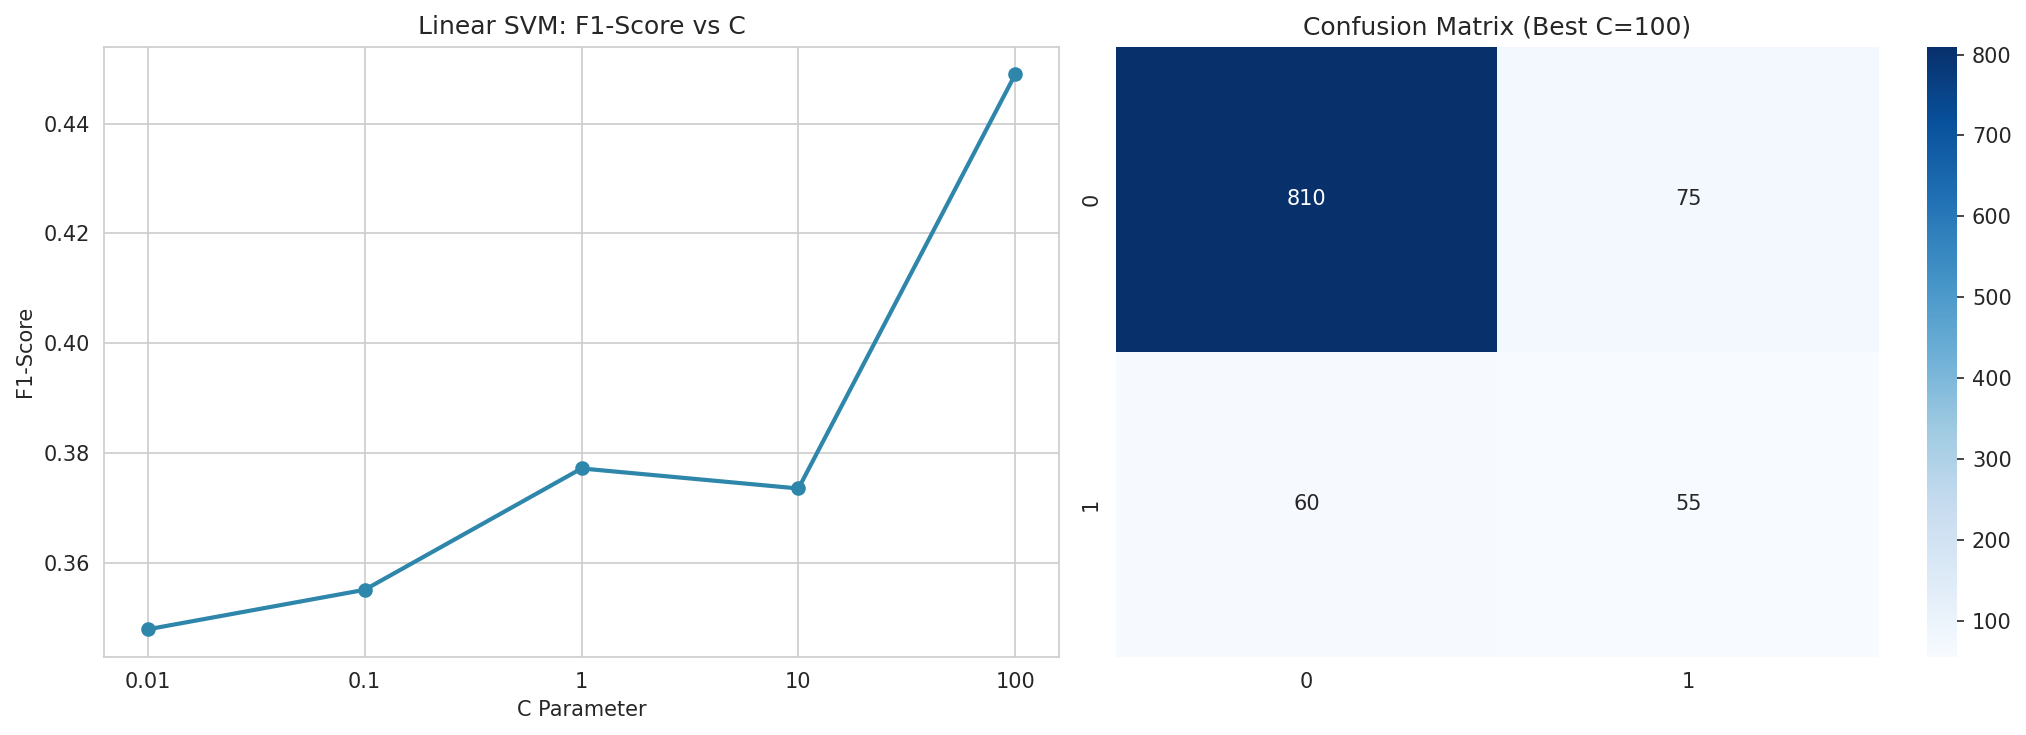

In [7]:
# --------------------------------------------------------------------------------------
# --- TASK 1 (LINEAR SVM TUNING) ---
# --------------------------------------------------------------------------------------
# Tune Regularization Parameter C. Generate F1 vs C plot and Confusion Matrix.

print("\n--- Task 1: Linear SVM (Tuning C) ---")
C_values = [0.01, 0.1, 1, 10, 100]
linear_results = []
best_linear_f1 = -1
best_linear_model = None

for C in C_values:
    print(f"Training Linear C={C}...")
    svm = SVM(kernel='linear', C=C, max_iter=MAX_ITER)
    svm.fit(X_train, y_train)

    metrics = calculate_metrics(y_test, svm.predict(X_test))
    metrics['C'] = C
    linear_results.append(metrics)
    print(f"   -> F1-Score: {metrics['F1-Score']:.4f}")

    if metrics['F1-Score'] > best_linear_f1:
        best_linear_f1 = metrics['F1-Score']
        best_linear_model = svm

# Visualizations
lin_df = pd.DataFrame(linear_results)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot F1 vs C
axes[0].plot([str(c) for c in C_values], lin_df['F1-Score'], marker='o', color='#2E86AB', linewidth=2)
axes[0].set_title('Linear SVM: F1-Score vs C')
axes[0].set_xlabel('C Parameter')
axes[0].set_ylabel('F1-Score')

# Plot Confusion Matrix
best_cm = calculate_metrics(y_test, best_linear_model.predict(X_test))['Confusion Matrix']
sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title(f'Confusion Matrix (Best C={best_linear_model.C})')

plt.tight_layout()
plt.savefig('task1_linear_svm.png', dpi=150)
plt.show()



--- Task 2: Polynomial SVM (Degrees 2-5) ---
Training Poly Degree=2...
   -> F1-Score: 0.4226
Training Poly Degree=3...
   -> F1-Score: 0.3303
Training Poly Degree=4...
   -> F1-Score: 0.2227
Training Poly Degree=5...
   -> F1-Score: 0.2063


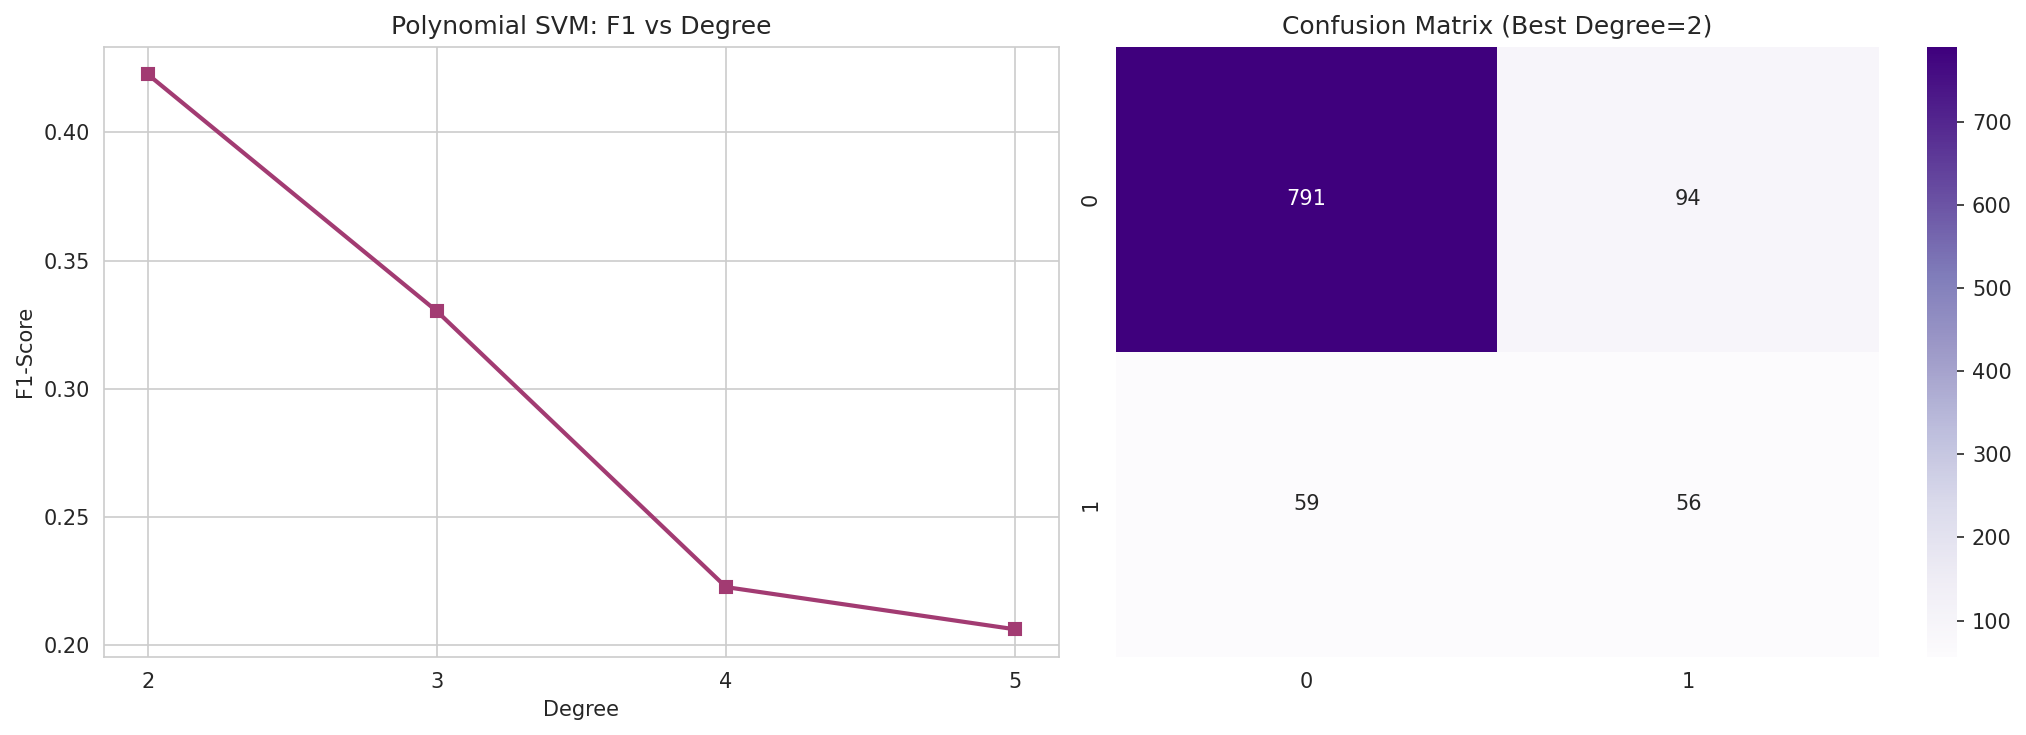

In [8]:
# --------------------------------------------------------------------------------------
# --- TASK 2 (POLYNOMIAL SVM TUNING) ---
# --------------------------------------------------------------------------------------
# Tune Polynomial Degree (2-5). Generate F1 vs Degree plot.

print("\n--- Task 2: Polynomial SVM (Degrees 2-5) ---")
degrees = [2, 3, 4, 5]
poly_results = []
best_poly_f1 = -1
best_poly_model = None

for d in degrees:
    print(f"Training Poly Degree={d}...")
    svm = SVM(kernel='poly', degree=d, C=1.0, max_iter=MAX_ITER)
    svm.fit(X_train, y_train)

    metrics = calculate_metrics(y_test, svm.predict(X_test))
    metrics['Degree'] = d
    poly_results.append(metrics)
    print(f"   -> F1-Score: {metrics['F1-Score']:.4f}")

    if metrics['F1-Score'] > best_poly_f1:
        best_poly_f1 = metrics['F1-Score']
        best_poly_model = svm

# Visualizations
poly_df = pd.DataFrame(poly_results)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot F1 vs Degree
axes[0].plot(poly_df['Degree'], poly_df['F1-Score'], marker='s', color='#A23B72', linewidth=2)
axes[0].set_title('Polynomial SVM: F1 vs Degree')
axes[0].set_xlabel('Degree')
axes[0].set_ylabel('F1-Score')
axes[0].set_xticks(degrees)

# Plot Confusion Matrix
best_poly_cm = calculate_metrics(y_test, best_poly_model.predict(X_test))['Confusion Matrix']
sns.heatmap(best_poly_cm, annot=True, fmt='d', cmap='Purples', ax=axes[1])
axes[1].set_title(f'Confusion Matrix (Best Degree={best_poly_model.degree})')

plt.tight_layout()
plt.savefig('task2_poly_svm.png', dpi=150)
plt.show()


--- Task 3: RBF SVM (Grid Search) ---
Testing C=0.1, Gamma=0.001... F1: 0.0000
Testing C=0.1, Gamma=0.01... F1: 0.0968
Testing C=0.1, Gamma=0.1... F1: 0.0000
Testing C=0.1, Gamma=1... F1: 0.0000
Testing C=1, Gamma=0.001... F1: 0.2895
Testing C=1, Gamma=0.01... F1: 0.3452
Testing C=1, Gamma=0.1... F1: 0.0630
Testing C=1, Gamma=1... F1: 0.0000
Testing C=10, Gamma=0.001... F1: 0.3669
Testing C=10, Gamma=0.01... F1: 0.4563
Testing C=10, Gamma=0.1... F1: 0.2000
Testing C=10, Gamma=1... F1: 0.0164
Testing C=100, Gamma=0.001... F1: 0.4316
Testing C=100, Gamma=0.01... F1: 0.5021
Testing C=100, Gamma=0.1... F1: 0.2439
Testing C=100, Gamma=1... F1: 0.0164


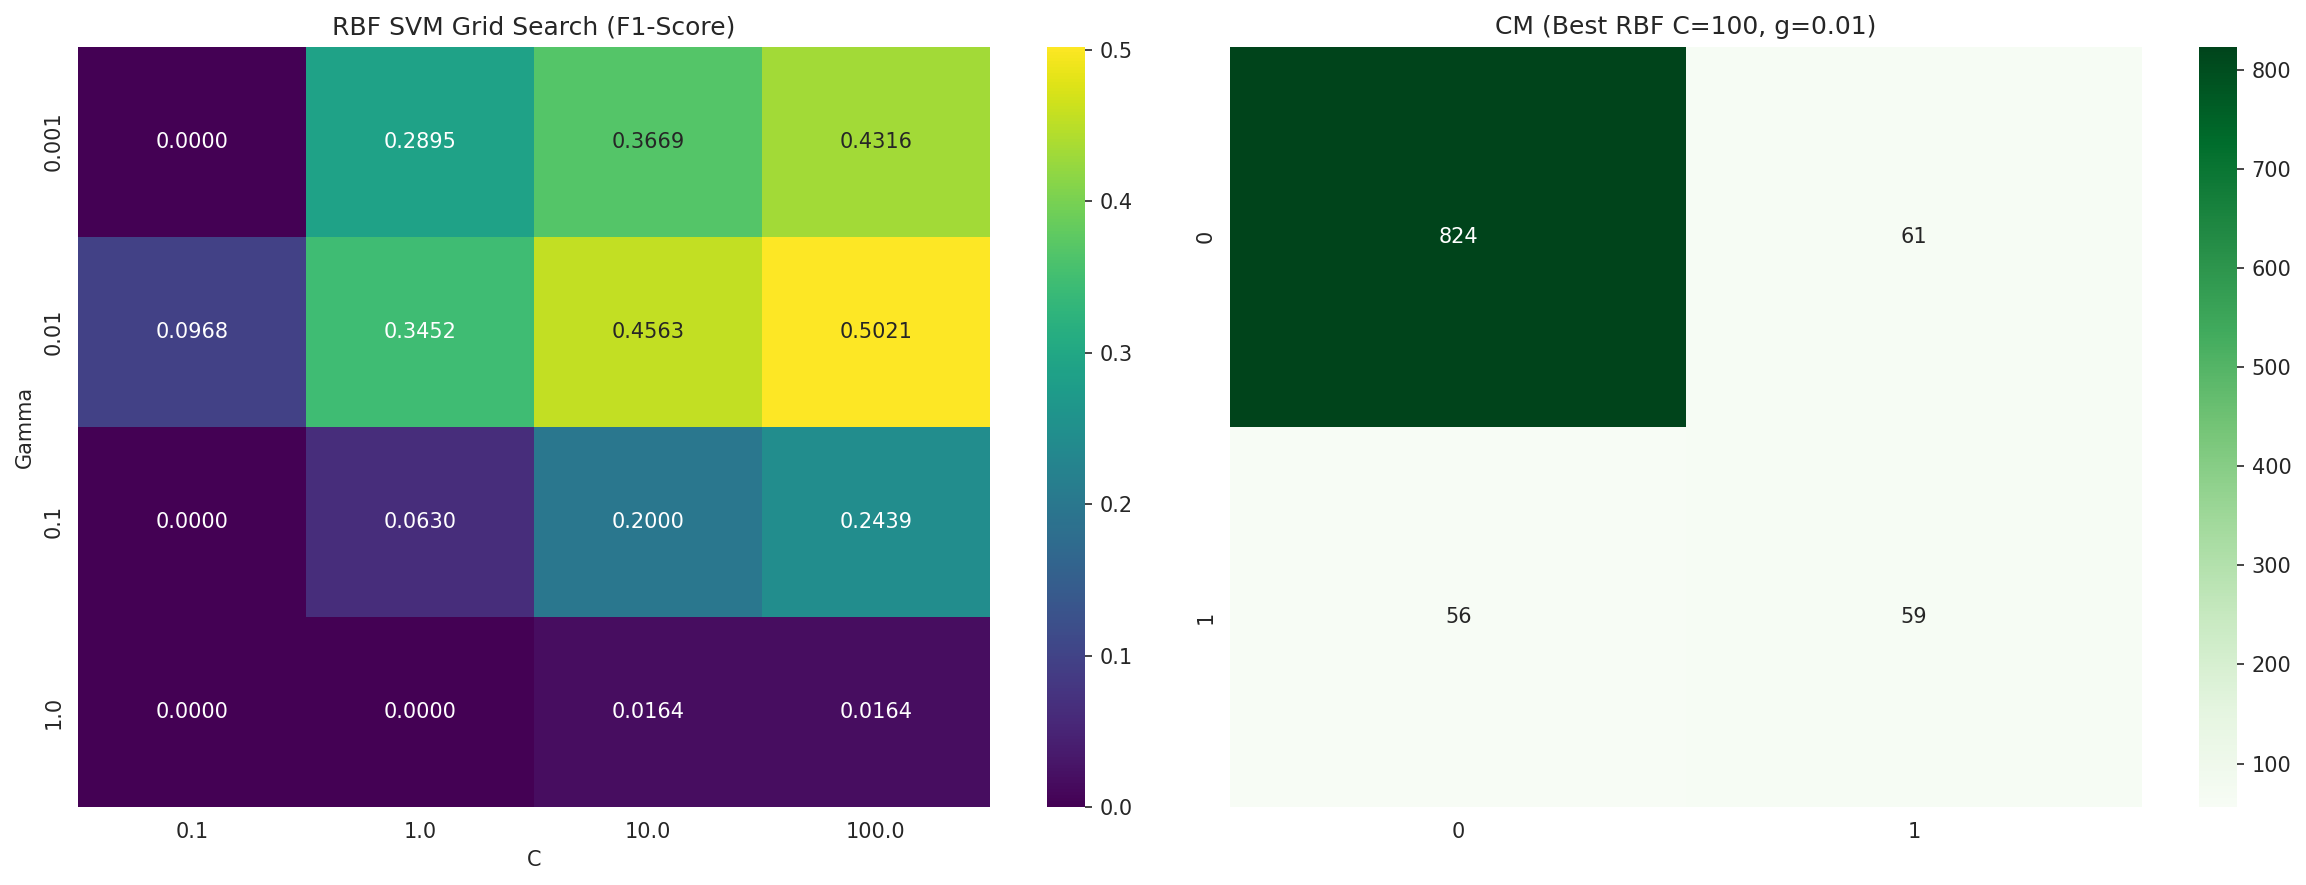

In [9]:
# --------------------------------------------------------------------------------------
# --- TASK 3 (RBF SVM GRID SEARCH) ---
# --------------------------------------------------------------------------------------
# Joint optimization of C and Gamma. Generate Heatmap.

print("\n--- Task 3: RBF SVM (Grid Search) ---")
C_rbf = [0.1, 1, 10, 100]
gamma_rbf = [0.001, 0.01, 0.1, 1]
rbf_results = []
best_rbf_f1 = -1
best_rbf_model = None

for C in C_rbf:
    for g in gamma_rbf:
        print(f"Testing C={C}, Gamma={g}...", end=" ")
        svm = SVM(kernel='rbf', C=C, gamma=g, max_iter=MAX_ITER)
        svm.fit(X_train, y_train)

        metrics = calculate_metrics(y_test, svm.predict(X_test))
        print(f"F1: {metrics['F1-Score']:.4f}")

        metrics['C'] = C
        metrics['Gamma'] = g
        rbf_results.append(metrics)

        if metrics['F1-Score'] > best_rbf_f1:
            best_rbf_f1 = metrics['F1-Score']
            best_rbf_model = svm

# Visualizations
rbf_df = pd.DataFrame(rbf_results)
pivot = rbf_df.pivot(index='Gamma', columns='C', values='F1-Score')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap
sns.heatmap(pivot, annot=True, fmt=".4f", cmap='viridis', ax=axes[0])
axes[0].set_title('RBF SVM Grid Search (F1-Score)')

# Best Confusion Matrix
best_rbf_cm = calculate_metrics(y_test, best_rbf_model.predict(X_test))['Confusion Matrix']
sns.heatmap(best_rbf_cm, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title(f'CM (Best RBF C={best_rbf_model.C}, g={best_rbf_model.gamma})')

plt.tight_layout()
plt.savefig('task3_rbf_svm.png', dpi=150)
plt.show()


--- Final Comparison ---
Training Sigmoid...

Final Performance Table:
   Model  Accuracy  Precision   Recall  F1-Score
  Linear     0.865   0.423077 0.478261  0.448980
    Poly     0.847   0.373333 0.486957  0.422642
     RBF     0.883   0.491667 0.513043  0.502128
 Sigmoid     0.834   0.278261 0.278261  0.278261
Ensemble     0.887   0.508065 0.547826  0.527197


/tmp/ipython-input-2713880911.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=final_df, x='Model', y='F1-Score', palette='viridis')


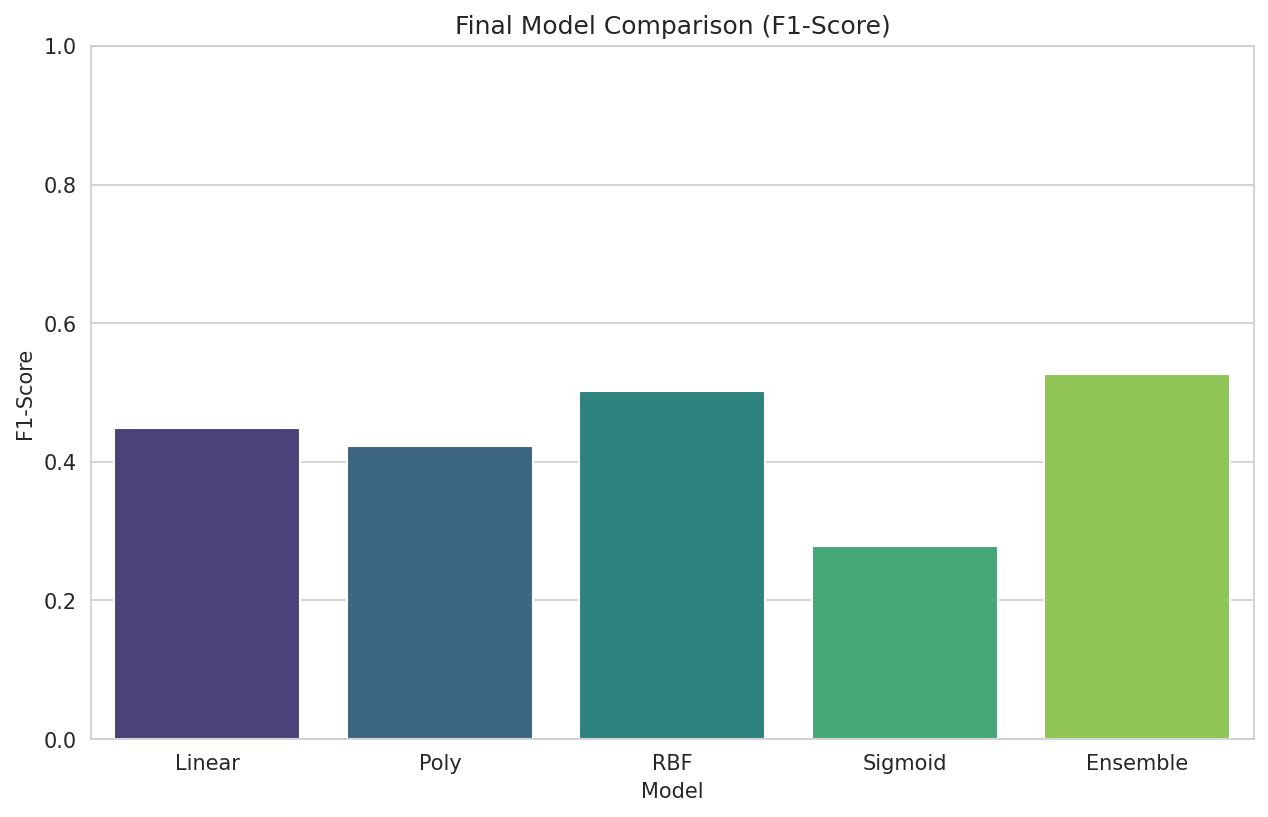

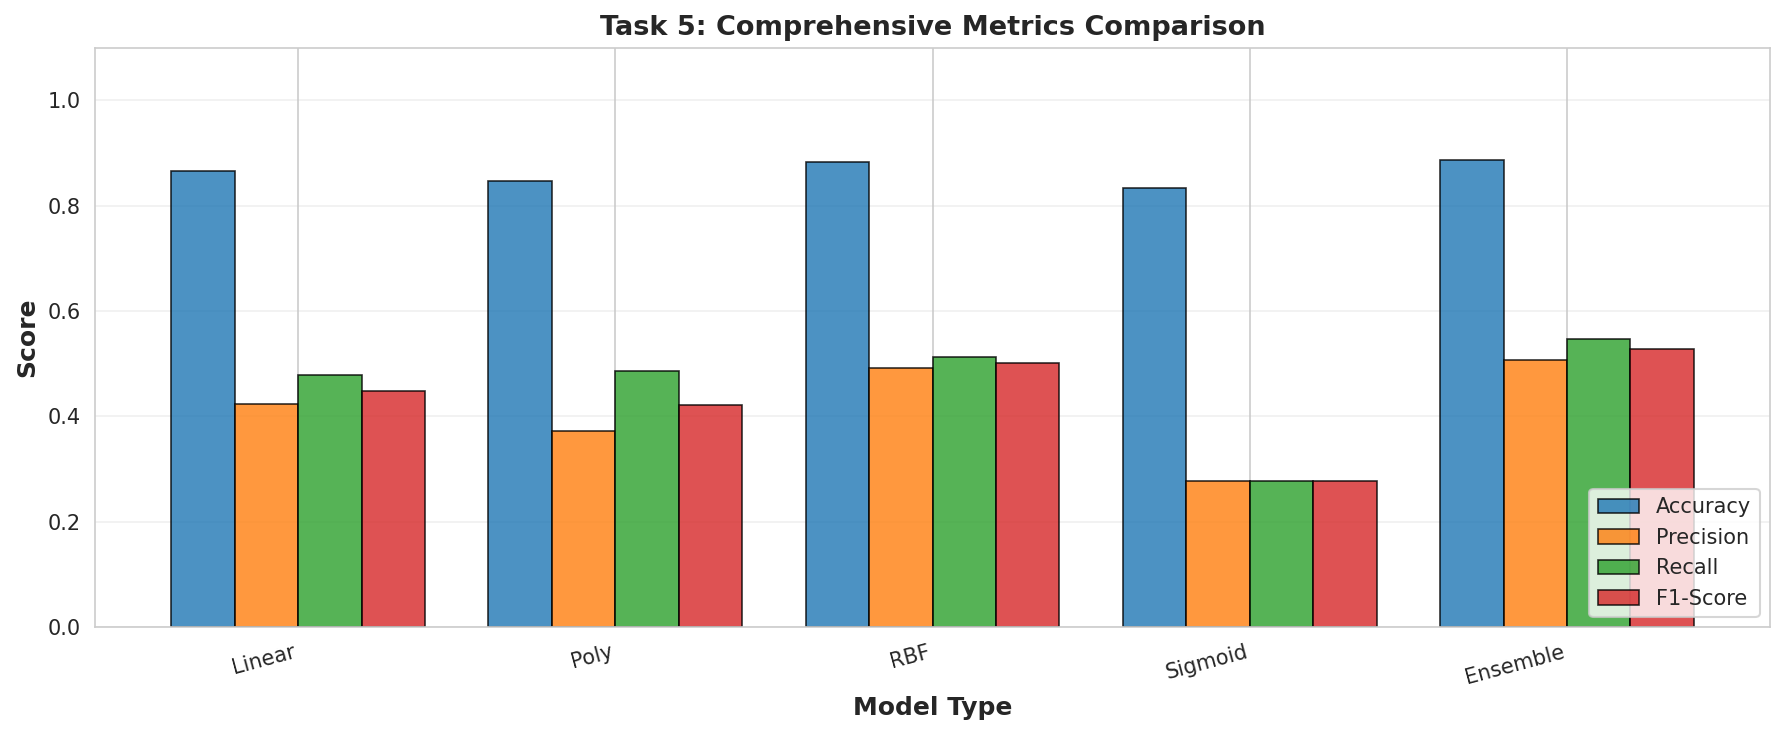

In [13]:
# --------------------------------------------------------------------------------------
# --- FINAL COMPARISON & ENSEMBLE ---
# --------------------------------------------------------------------------------------
# Compare best models + Ensemble (Majority Vote).

print("\n--- Final Comparison ---")

# Train Sigmoid for completeness
print("Training Sigmoid...")
sigmoid = SVM(kernel='sigmoid', C=1.0, gamma=0.1, max_iter=MAX_ITER)
sigmoid.fit(X_train, y_train)

# Create Ensemble (Majority Vote)
p1 = np.sign(best_linear_model.predict(X_test))
p2 = np.sign(best_poly_model.predict(X_test))
p3 = np.sign(best_rbf_model.predict(X_test))
ensemble_pred = np.sign(p1 + p2 + p3)
ensemble_pred[ensemble_pred == 0] = 1 # Handle ties

# Compile Results Table
final_results = []
models = [
    ('Linear', best_linear_model),
    ('Poly', best_poly_model),
    ('RBF', best_rbf_model),
    ('Sigmoid', sigmoid)
]

for name, model in models:
    m = calculate_metrics(y_test, model.predict(X_test))
    m['Model'] = name
    final_results.append(m)

# Add Ensemble results
m_ens = calculate_metrics(y_test, ensemble_pred)
m_ens['Model'] = 'Ensemble'
final_results.append(m_ens)

# Display Table
final_df = pd.DataFrame(final_results)
cols = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
print("\nFinal Performance Table:")
print(final_df[cols].to_string(index=False))

# Plot Comparison
plt.figure(figsize=(10, 6))
sns.barplot(data=final_df, x='Model', y='F1-Score', palette='viridis')
plt.title('Final Model Comparison (F1-Score)')
plt.ylim(0, 1.0)
plt.savefig('task5_comparison.png', dpi=150)
plt.show()

# Prepare comparison DF and labels
comparison_df = final_df.set_index('Model')  # or: comparison_df = final_df.copy()
models = comparison_df.index.tolist()
metrics_data = comparison_df[['Accuracy','Precision','Recall','F1-Score']].astype(float).values

# Create single axis for comprehensive metrics comparison
fig, ax = plt.subplots(figsize=(12, 5))

# Grouped bar plot
x_pos = np.arange(len(models))
width = 0.2
for i, metric in enumerate(['Accuracy','Precision','Recall','F1-Score']):
    offset = width * (i - 1.5)
    ax.bar(x_pos + offset, metrics_data[:, i], width,
           label=metric, alpha=0.8, edgecolor='black', linewidth=0.8)

ax.set_xlabel('Model Type', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Task 5: Comprehensive Metrics Comparison', fontsize=13, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(models, rotation=15, ha='right')
ax.legend(loc='lower right', fontsize=10)

ax.set_ylim([0, 1.1])
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('task5_final_comparison.png', dpi=150, bbox_inches='tight')
plt.show()